# SiteScore — 02 Modelling

**MGSC 661 group project.** This notebook fits the logistic regression behind SiteScore: what is associated with a restaurant being permanently closed at the Yelp snapshot?

**Workflow**

```
outputs/restaurants_clean.csv   (from notebook 01)
   │  Step 1  load and check the inputs
   │  Step 2  modelling choices: reference levels, scaling, the formula for each block
   │  Step 3  build the model in four blocks; compare fit (likelihood-ratio tests, AIC, BIC, pseudo R², AUC)
   │  Step 4  final model: odds ratios, confidence intervals, significance, joint tests
   │  Step 5  robustness of the significance: standard errors clustered by neighbourhood
   │  Step 6  diagnostics: multicollinearity, linearity of the logit, influence, calibration, residuals
   ▼  Step 7  save outputs
outputs/block_comparison.csv · odds_ratios_final.csv · model_formula.txt · ../reports/figures/odds_ratios.png
```

**The model.** For restaurant *i*, with *p* = P(closed = 1):

$$\log\frac{p_i}{1-p_i} = \beta_0 + \underbrace{\text{price tier} + \text{cuisine} + \text{chain}}_{\text{Block 1: concept}} + \underbrace{\text{density} + \text{same-cuisine share}}_{\text{Block 2: competition}} + \underbrace{|\text{price gap}| + \text{gap missing}}_{\text{Block 3: price positioning}} + \underbrace{\text{metro}}_{\text{Block 4: market}}$$

**What this notebook does not do.** Every fit statistic here is **in-sample**. Out-of-sample performance (held-out metro, naive baseline, AUC, calibration) belongs to notebook 03. The leakage rule from notebook 01 still applies: no ratings, review counts, check-ins or neighbours' closure flags are used.

## Step 0 — Settings

In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_auc_score

DATA_PATH = "outputs/restaurants_clean.csv"
OUTPUT_DIR = "outputs"
FIG_DIR = "../reports/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Reference (baseline) level of each categorical variable; Step 2 explains the choices
REF_PRICE = "1"
REF_CUISINE = "Burgers & Fast Food"
REF_METRO = "Philadelphia"

ALPHA = 0.05
GREEN, RUST, GREY = "#1f4e3d", "#b5543c", "#8a8a8a"   # same colours as notebook 01

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## Step 1 — Load and check the inputs

We read the table written by notebook 01 and keep the eight inputs recommended in its `decisions_log.md`, plus the target. `price_tier` is read as text so that `"1"`…`"4"` and `"Missing"` stay categories rather than becoming numbers.

Checks before modelling:
- the row count and closure rate match notebook 01 (52,268 restaurants, 33.1% closed);
- no model variable has missing values (logistic regression would silently drop those rows);
- every category has enough restaurants **and** enough closures. A category with very few closures (or none) gives unstable or infinite odds ratios, a problem called *separation*.

In [2]:
df = pd.read_csv(DATA_PATH, dtype={"price_tier": str})

TARGET = "closed"
INPUTS = ["price_tier", "cuisine_group", "is_chain", "log_n_rest_500m", "same_cuisine_share_500m",
          "abs_price_gap", "price_gap_missing", "metro"]

print(f"Restaurants: {len(df):,}   closed: {df[TARGET].sum():,} ({df[TARGET].mean():.1%})")
print("Missing values in model variables:", int(df[[TARGET] + INPUTS].isna().sum().sum()))

print("\nSmallest cells (restaurants and closures per category):")
cells = []
for col in ["price_tier", "cuisine_group", "metro", "is_chain", "price_gap_missing"]:
    t = df.groupby(col)[TARGET].agg(n="size", closed="sum", closed_share="mean")
    t.index = [f"{col} = {i}" for i in t.index]
    cells.append(t)
cells = pd.concat(cells).sort_values("closed")
display(cells.head(6).round(3))

print("Continuous inputs:")
display(df[["log_n_rest_500m", "same_cuisine_share_500m", "abs_price_gap"]].describe().round(3))

Restaurants: 52,268   closed: 17,281 (33.1%)
Missing values in model variables: 0

Smallest cells (restaurants and closures per category):


,n,closed,closed_share
price_tier = 4,194,81,0.418
metro = Boise,1302,362,0.278
metro = Santa Barbara,1160,493,0.425
metro = Reno,1673,598,0.357
metro = Edmonton,2410,676,0.280
cuisine_group = Mediterranean & Mid-East,1569,681,0.434


Continuous inputs:


,log_n_rest_500m,same_cuisine_share_500m,abs_price_gap
count,52268.000,52268.000,52268.000
mean,2.902,0.116,0.387
std,1.250,0.145,0.347
min,0.000,0.000,0.000
25%,2.197,0.000,0.066
50%,2.833,0.081,0.346
75%,3.555,0.159,0.600
max,6.330,1.000,3.000


**Reading the checks.** The counts match notebook 01 and nothing is missing. The smallest cell is the most expensive price tier (`price_tier = 4`), with under 200 restaurants and about 80 closures. That is enough to estimate an odds ratio, but its confidence interval will be wide. No category is close to separation.

## Step 2 — Modelling choices

**Reference levels.** A categorical variable with *k* levels enters as *k* − 1 dummy variables, and each odds ratio compares one level with the reference level. We pick references that make the comparisons easy to read:

| Variable | Reference | Why |
|---|---|---|
| `price_tier` | `1` ($) | The natural starting point: the other levels read as "more expensive than $" or "price not reported" |
| `cuisine_group` | `Burgers & Fast Food` | The largest group, so the comparisons are precise; also the format with the lowest closure rate, so most odds ratios are above 1 |
| `metro` | `Philadelphia` | The largest metro (a third of the data) |

**Scaling the continuous inputs.** An odds ratio describes a one-unit change, so the unit should mean something:

| Variable | One unit means | Odds ratio reads as |
|---|---|---|
| `log_n_rest_500m` | the count of nearby restaurants multiplied by *e* ≈ 2.7 | We also report the effect of **doubling** the count: OR<sup>ln 2</sup> |
| `same_cuisine_share_10pp` | the share of nearby restaurants with the same cuisine, **+10 percentage points** | The raw share runs 0–1, so a one-unit change (0% → 100%) is unrealistic. We divide by 0.1 |
| `abs_price_gap` | one full price tier above or below the neighbourhood average | As is |

**How the price variables fit together.** `price_gap_missing` is 1 for every restaurant with `price_tier = Missing` (it has no own price) and also for about 1,400 restaurants that report a price but have no priced neighbours within 500 m. The `Missing` price-tier dummy already absorbs the first group, so the `price_gap_missing` coefficient is identified only by the second. For those restaurants `abs_price_gap` is set to 0, and the flag stops that 0 from being read as "priced exactly like the neighbourhood".

**Why build in blocks.** Adding one group of variables at a time shows (a) how much each group adds over the previous ones, tested with a likelihood-ratio test, and (b) whether earlier coefficients change once later variables are controlled for. A coefficient that moves a lot when a block enters was partly picking up that block's effect.

In [3]:
df["same_cuisine_share_10pp"] = df["same_cuisine_share_500m"] * 10

PRICE = f"C(price_tier, Treatment('{REF_PRICE}'))"
CUISINE = f"C(cuisine_group, Treatment('{REF_CUISINE}'))"
METRO = f"C(metro, Treatment('{REF_METRO}'))"

BLOCKS = {
    "B1 Concept":           [PRICE, CUISINE, "is_chain"],
    "B2 + Competition":     ["log_n_rest_500m", "same_cuisine_share_10pp"],
    "B3 + Price position":  ["abs_price_gap", "price_gap_missing"],
    "B4 + Metro":           [METRO],
}

formulas, terms = {}, []
for name, block_terms in BLOCKS.items():
    terms += block_terms
    formulas[name] = f"{TARGET} ~ " + " + ".join(terms)
for name, f in formulas.items():
    print(f"{name}:\n   {f}\n")

B1 Concept:
   closed ~ C(price_tier, Treatment('1')) + C(cuisine_group, Treatment('Burgers & Fast Food')) + is_chain

B2 + Competition:
   closed ~ C(price_tier, Treatment('1')) + C(cuisine_group, Treatment('Burgers & Fast Food')) + is_chain + log_n_rest_500m + same_cuisine_share_10pp

B3 + Price position:
   closed ~ C(price_tier, Treatment('1')) + C(cuisine_group, Treatment('Burgers & Fast Food')) + is_chain + log_n_rest_500m + same_cuisine_share_10pp + abs_price_gap + price_gap_missing

B4 + Metro:
   closed ~ C(price_tier, Treatment('1')) + C(cuisine_group, Treatment('Burgers & Fast Food')) + is_chain + log_n_rest_500m + same_cuisine_share_10pp + abs_price_gap + price_gap_missing + C(metro, Treatment('Philadelphia'))



A few helpers: `fit_logit` fits one model (statsmodels `GLM` with a binomial family and logit link, i.e. maximum-likelihood logistic regression), and `nice_label` turns statsmodels' term names, such as `C(metro, Treatment('Philadelphia'))[T.Tampa]`, into readable labels.

In [4]:
def fit_logit(formula, data=df, **fit_kwargs):
    return smf.glm(formula, data=data, family=sm.families.Binomial()).fit(**fit_kwargs)

PRETTY = {
    "is_chain": "Chain (5+ locations)",
    "log_n_rest_500m": "log(1 + restaurants within 500 m)",
    "same_cuisine_share_10pp": "Same-cuisine share, +10 pp",
    "abs_price_gap": "|Price gap| (tiers)",
    "price_gap_missing": "Price gap missing",
    "Intercept": "Intercept",
}
VAR_NAMES = {"price_tier": "Price tier", "cuisine_group": "Cuisine", "metro": "Metro"}

def nice_label(term):
    m = re.match(r"C\((\w+), Treatment\('(.+?)'\)\)\[T\.(.+)\]", term)
    if m:
        var, ref, level = m.groups()
        return f"{VAR_NAMES.get(var, var)}: {level} (vs {ref})"
    return PRETTY.get(term, term)

def block_of(term):
    for name, block_terms in BLOCKS.items():
        if any(term == t or term.startswith(t + "[") for t in block_terms):
            return name
    return ""

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

## Step 3 — Build the model in blocks

| Block | Adds | Question it answers |
|---|---|---|
| B1 Concept | price tier, cuisine group, chain flag | What the founder chooses: what kind of restaurant is it? |
| B2 Competition | log density within 500 m, same-cuisine share | Does the crowdedness of the site matter, once the concept is known? |
| B3 Price position | absolute price gap to neighbours, gap-missing flag | Does standing out on price from the neighbourhood matter? |
| B4 Metro | 10 metro dummies | Are there market-wide differences left over, such as local economy, rents or Yelp coverage? |

For each block we report:
- **Log-likelihood** and the **likelihood-ratio (LR) test** against the previous block: LR = 2 × (LL<sub>new</sub> − LL<sub>old</sub>), compared with a χ² distribution whose degrees of freedom equal the number of added parameters. A small p-value means the new block improves fit by more than chance.
- **AIC** and **BIC**: fit penalised for the number of parameters (lower is better). BIC penalises much harder (ln *n* ≈ 10.9 per parameter here versus 2 for AIC).
- **McFadden pseudo R²** = 1 − LL<sub>model</sub> / LL<sub>null</sub>. It is not the share of variance explained; values of 0.05–0.2 are typical for individual-level outcomes like this one.
- **AUC (in-sample)**: the probability that a randomly chosen closed restaurant gets a higher predicted risk than a randomly chosen open one. 0.5 is a coin flip.

In [5]:
null_model = fit_logit(f"{TARGET} ~ 1")
models = {"B0 Null": null_model}
for name, f in formulas.items():
    models[name] = fit_logit(f)

rows, prev = [], None
for name, m in models.items():
    row = {"block": name, "parameters": int(m.df_model) + 1, "log_likelihood": m.llf,
           "AIC": m.aic, "BIC": m.bic_llf,
           "McFadden_R2": 1 - m.llf / null_model.llf,
           "AUC_in_sample": roc_auc_score(df[TARGET], m.fittedvalues) if prev is not None else 0.5}
    if prev is not None:
        lr = 2 * (m.llf - prev.llf)
        d = int(m.df_model - prev.df_model)
        row.update(LR_stat=lr, LR_df=d, LR_p=stats.chi2.sf(lr, d))
    rows.append(row)
    prev = m

block_comparison = pd.DataFrame(rows).set_index("block")
display(block_comparison.style.format({
    "log_likelihood": "{:,.1f}", "AIC": "{:,.0f}", "BIC": "{:,.0f}", "McFadden_R2": "{:.4f}",
    "AUC_in_sample": "{:.3f}", "LR_stat": "{:,.1f}", "LR_df": "{:.0f}", "LR_p": "{:.1e}"}, na_rep="–"))

,parameters,log_likelihood,AIC,BIC,McFadden_R2,AUC_in_sample,LR_stat,LR_df,LR_p
block,,,,,,,,,
B0 Null,1,"-33,170.3","66,343","66,351",0.0000,0.500,–,–,–
B1 Concept,19,"-31,364.4","62,767","62,935",0.0544,0.655,"3,611.7",18,0.0e+00
B2 + Competition,21,"-30,985.1","62,012","62,198",0.0659,0.674,758.5,2,1.9e-165
B3 + Price position,23,"-30,975.1","61,996","62,200",0.0662,0.674,20.1,2,4.3e-05
B4 + Metro,33,"-30,925.4","61,917","62,209",0.0677,0.675,99.4,10,7.2e-17


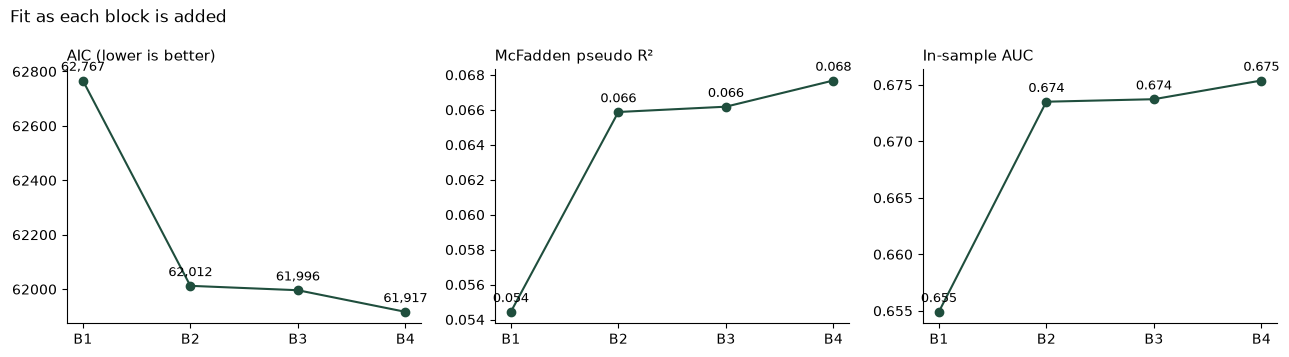

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
labels = [b.split(" ", 1)[0] for b in block_comparison.index]
for ax, col, title in zip(axes, ["AIC", "McFadden_R2", "AUC_in_sample"],
                          ["AIC (lower is better)", "McFadden pseudo R²", "In-sample AUC"]):
    vals = block_comparison[col].iloc[1:]
    ax.plot(labels[1:], vals, marker="o", color=GREEN)
    for x, v in zip(labels[1:], vals):
        ax.annotate(f"{v:,.0f}" if col == "AIC" else f"{v:.3f}", (x, v), textcoords="offset points",
                    xytext=(0, 7), ha="center", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Fit as each block is added", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

**Reading the block comparison.**

- **Every block improves fit significantly** (all LR p-values far below 0.001), but by very different amounts.
- **Concept (B1)** does most of the work: price tier, cuisine and chain status alone take the in-sample AUC from 0.50 to about 0.65.
- **Competition (B2)** is the largest single addition after that: an LR statistic of about 760 on just 2 parameters, and the AUC rises to about 0.67. Where a restaurant opens matters, over and above what kind of restaurant it is.
- **Price position (B3)** is significant but small (LR ≈ 20 on 2 parameters, AUC almost unchanged).
- **Metro (B4)** is significant by the LR test and AIC, but **BIC rises slightly** because of its 10 parameters. We keep metro in the main model as a control, so the other effects are estimated *within* metros and are not driven by, say, Philadelphia having both dense neighbourhoods and a high closure rate. Notebook 03 should keep in mind that a held-out metro has no metro coefficient (see the hand-off notes at the end).
- In absolute terms the model is modest (McFadden R² ≈ 0.07, AUC ≈ 0.675). That is expected: rent, management, capital and luck are not in the data. The goal is an interpretable risk ranking, not a perfect classifier.

### 3b. Do the coefficients hold up as blocks are added?

Odds ratios of the main variables in each block (blank = not yet in the model). If an odds ratio moves a lot when a block enters, part of the earlier estimate was really that block's effect (confounding).

In [7]:
track = ["is_chain", f"{PRICE}[T.2]", f"{PRICE}[T.3]", f"{PRICE}[T.4]", f"{PRICE}[T.Missing]",
         f"{CUISINE}[T.American]", f"{CUISINE}[T.Italian]",
         "log_n_rest_500m", "same_cuisine_share_10pp", "abs_price_gap", "price_gap_missing"]
stability = pd.DataFrame({name: np.exp(m.params).reindex(track) for name, m in models.items() if name != "B0 Null"})
stability.index = [nice_label(t) for t in track]
display(stability.style.format("{:.3f}", na_rep=""))

,B1 Concept,B2 + Competition,B3 + Price position,B4 + Metro
Chain (5+ locations),0.355,0.359,0.360,0.357
Price tier: 2 (vs 1),1.043,0.998,1.031,1.041
Price tier: 3 (vs 1),1.160,1.004,0.898,0.922
Price tier: 4 (vs 1),0.974,0.846,0.641,0.662
Price tier: Missing (vs 1),0.429,0.426,0.428,0.427
Cuisine: American (vs Burgers & Fast Food),2.011,2.181,2.179,2.167
Cuisine: Italian (vs Burgers & Fast Food),1.559,1.615,1.617,1.609
log(1 + restaurants within 500 m),,1.235,1.237,1.246
"Same-cuisine share, +10 pp",,1.043,1.044,1.043
|Price gap| (tiers),,,1.197,1.191


**Reading the stability table.**

- **Chain status** is very stable (OR ≈ 0.36 in every block). Being a chain is not standing in for location or price.
- **The upper price tiers change most.** In the raw data $$$ restaurants close far more often than $ (46.7% versus 30.3%). With cuisine and chain controlled (B1) the gap is already down to OR ≈ 1.16; once density enters (B2) it disappears (≈ 1.00): pricier restaurants cluster in dense, high-turnover districts, and the density carries the risk. When the price gap enters (B3), tier 3 drops to ≈ 0.90 and **tier 4 from ≈ 0.85 to ≈ 0.64**. A $$$$ restaurant is almost always far from its neighbourhood's average price, so part of the risk first attributed to "being expensive" is really "being out of line with the area".
- **American restaurants** look riskier once density is controlled (OR 2.01 → 2.18): they are more often in quiet, low-density areas, which hides part of their risk in B1.
- **Density and same-cuisine share** barely change after B2, and **the B4 odds ratios are close to B3's**, so adding metro does not overturn any conclusion.

## Step 4 — Final model: odds ratios and significance

The final model is block B4. Its full statsmodels summary comes first (coefficients on the log-odds scale), then the table we interpret: **odds ratios** OR = e<sup>β</sup>, with 95% confidence intervals e<sup>β ± 1.96·SE</sup> and Wald p-values.

How to read an odds ratio: OR = 1.25 means the *odds* of being closed are 25% higher, holding all other variables fixed; OR = 0.36 means they are 64% lower. Odds are not probabilities. When the baseline risk is around 33%, a 25% rise in odds corresponds to roughly a 5-percentage-point rise in probability.

In [8]:
FINAL = "B4 + Metro"
final = models[FINAL]
print(final.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 closed   No. Observations:                52268
Model:                            GLM   Df Residuals:                    52235
Model Family:                Binomial   Df Model:                           32
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -30925.
Date:                Tue, 24 Nov 2026   Deviance:                       61851.
Time:                        17:38:58   Pearson chi2:                 5.23e+04
No. Iterations:                     4   Pseudo R-squ. (CS):            0.08231
Covariance Type:            nonrobust                                         
                                                                                     coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------

In [9]:
ci = final.conf_int()
or_table = pd.DataFrame({
    "block": [block_of(t) for t in final.params.index],
    "odds_ratio": np.exp(final.params),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1]),
    "coef": final.params,
    "std_err": final.bse,
    "z": final.tvalues,
    "p_value": final.pvalues,
})
or_table["sig"] = or_table["p_value"].map(stars)
or_table.index = [nice_label(t) for t in or_table.index]

display(or_table.drop(index="Intercept").style
        .format({"odds_ratio": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "coef": "{:.3f}",
                 "std_err": "{:.3f}", "z": "{:.2f}", "p_value": "{:.2g}"})
        .background_gradient(subset=["odds_ratio"], cmap="RdYlGn_r", vmin=0.4, vmax=2.2))
print("Significance: *** p < 0.001, ** p < 0.01, * p < 0.05")

b = final.params["log_n_rest_500m"]
lo, hi = ci.loc["log_n_rest_500m"]
print(f"\nDoubling the number of nearby restaurants: OR = {2**b:.3f} (95% CI {2**lo:.3f}–{2**hi:.3f})")

,block,odds_ratio,ci_low,ci_high,coef,std_err,z,p_value,sig
Price tier: 2 (vs 1),B1 Concept,1.041,0.993,1.091,0.040,0.024,1.65,0.099,
Price tier: 3 (vs 1),B1 Concept,0.922,0.818,1.040,-0.081,0.061,-1.31,0.19,
Price tier: 4 (vs 1),B1 Concept,0.662,0.478,0.917,-0.412,0.166,-2.48,0.013,*
Price tier: Missing (vs 1),B1 Concept,0.427,0.369,0.494,-0.851,0.075,-11.39,4.9e-30,***
Cuisine: American (vs Burgers & Fast Food),B1 Concept,2.167,1.975,2.377,0.773,0.047,16.36,3.6e-60,***
Cuisine: Bars & Pubs (vs Burgers & Fast Food),B1 Concept,1.202,1.089,1.326,0.184,0.050,3.66,0.00025,***
Cuisine: Cafes & Breakfast (vs Burgers & Fast Food),B1 Concept,1.132,1.039,1.233,0.124,0.044,2.84,0.0045,**
Cuisine: Chinese (vs Burgers & Fast Food),B1 Concept,0.844,0.759,0.940,-0.169,0.055,-3.09,0.002,**
Cuisine: Italian (vs Burgers & Fast Food),B1 Concept,1.609,1.435,1.803,0.475,0.058,8.18,2.9e-16,***
Cuisine: Japanese & Sushi (vs Burgers & Fast Food),B1 Concept,1.102,0.990,1.226,0.097,0.055,1.77,0.077,


Significance: *** p < 0.001, ** p < 0.01, * p < 0.05

Doubling the number of nearby restaurants: OR = 1.164 (95% CI 1.151–1.178)


### 4b. Joint significance of each variable

A Wald test for a multi-level categorical variable tests all its dummies at once (H<sub>0</sub>: every level has the same odds as the reference). This answers "does cuisine matter?", which the individual p-values cannot.

In [10]:
wald = final.wald_test_terms(scalar=True).table
wald.index = [VAR_NAMES.get(re.sub(r"C\((\w+),.*", r"\1", t), PRETTY.get(t, t)) for t in wald.index]
wald = wald.rename(columns={"statistic": "chi2", "pvalue": "p_value", "df_constraint": "df"})
display(wald[["chi2", "df", "p_value"]].drop(index="Intercept")
        .style.format({"chi2": "{:,.1f}", "df": "{:.0f}", "p_value": "{:.2g}"}))

,chi2,df,p_value
Price tier,147.9,4,5.8e-31
Cuisine,566.7,13,9.7e-113
Metro,98.4,10,1.2e-16
Chain (5+ locations),"1,235.1",1,1.4e-270
log(1 + restaurants within 500 m),647.3,1,8.5e-143
"Same-cuisine share, +10 pp",33.0,1,9.2e-09
|Price gap| (tiers),18.8,1,1.4e-05
Price gap missing,2.3,1,0.13


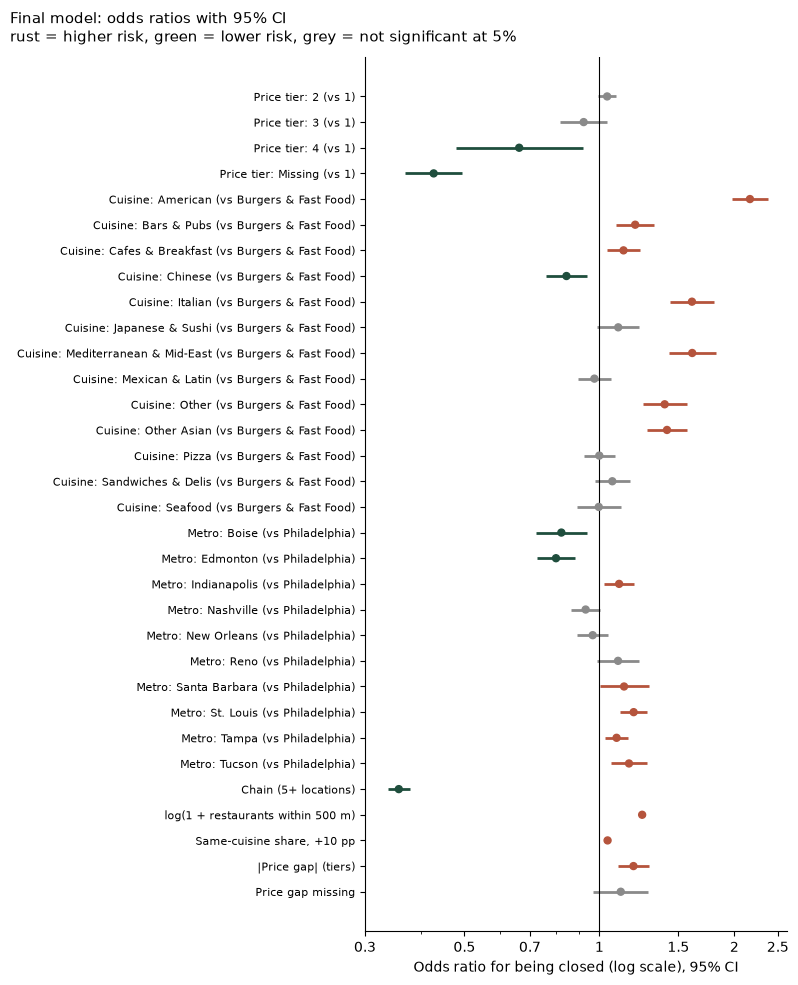

In [11]:
plot_df = or_table.drop(index="Intercept").iloc[::-1]
colors = [GREY if p >= ALPHA else (RUST if o > 1 else GREEN) for o, p in zip(plot_df["odds_ratio"], plot_df["p_value"])]

fig, ax = plt.subplots(figsize=(8, 10))
y = np.arange(len(plot_df))
ax.hlines(y, plot_df["ci_low"], plot_df["ci_high"], color=colors, linewidth=2)
ax.scatter(plot_df["odds_ratio"], y, color=colors, zorder=3, s=25)
ax.axvline(1, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 0.7, 1, 1.5, 2, 2.5])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FormatStrFormatter("%g"))
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlabel("Odds ratio for being closed (log scale), 95% CI")
fig.suptitle("Final model: odds ratios with 95% CI\nrust = higher risk, green = lower risk, grey = not significant at 5%",
             x=0.01, ha="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "odds_ratios.png"), dpi=200)
plt.show()

**Interpreting the final model** (all effects hold the other variables fixed):

- **Chains are much safer.** A chain's odds of being closed are about **64% lower** than an independent's (OR ≈ 0.36). This is the strongest single effect in the model. Brand, systems and capital are plausible reasons; the model cannot say which.
- **Density is the main location risk.** Each doubling of the number of restaurants within 500 m raises the odds of closure by about **16%** (OR ≈ 1.25 per log unit). Busy restaurant districts have more turnover, even after cuisine, price and metro are controlled for.
- **Same-cuisine competition adds a little.** Read literally, each extra 10 percentage points of same-cuisine neighbours raises the odds by about **4%**. The diagnostics in Step 6b show the real pattern is different: the risk comes from having **at least one** same-cuisine competitor within 500 m (about 28% higher odds), and more saturation beyond that adds nothing. Describe it that way in the report.
- **Standing out on price is slightly riskier.** Each full price tier away from the neighbourhood average, in either direction, raises the odds by about **19%** (OR ≈ 1.19).
- **Price tier itself matters little once location is known.** Tiers 2 and 3 are not significantly different from $. Tier 4 ($$$$) is somewhat safer (OR ≈ 0.66, wide interval). **"Missing" price has much lower odds (OR ≈ 0.43)**. That is probably a Yelp-data artifact rather than a real effect: newer listings, or listings with little activity, tend to have fewer attributes filled in, and a restaurant that closed long ago had less time to collect them. It should not be read as "don't publish your prices".
- **Cuisine matters jointly** (Wald test above). Compared with burgers and fast food, American (OR ≈ 2.2), Italian and Mediterranean (≈ 1.6), Other Asian and Other (≈ 1.4) have higher odds of closure; Chinese is slightly lower (≈ 0.84). Pizza, Mexican, Seafood, Sandwiches and Japanese are not significantly different from the reference.
- **Metro differences are modest** (ORs 0.80–1.19 against Philadelphia), but jointly significant.
- `price_gap_missing` is not significant on its own (p ≈ 0.13): among restaurants that report a price, having no priced neighbours does not change risk much.

**A caution on p-values.** With 52,000 observations, even tiny effects become "significant". The size of the odds ratio and its confidence interval matter more than the stars. Step 5 also checks whether the standard errors are too small because nearby restaurants are not independent.

## Step 5 — Robustness of the significance: clustered standard errors

The usual logistic-regression standard errors assume every restaurant is an independent observation. Restaurants on the same street share unobserved conditions (rent, foot traffic, a road closure), so their outcomes are probably correlated, which makes the default standard errors **too small**.

We re-estimate the same model with **cluster-robust standard errors**, grouping restaurants into 2 km × 2 km grid cells. The coefficients (and odds ratios) do not change; only the standard errors, confidence intervals and p-values do. (Clustering by metro would be the obvious alternative, but 11 clusters are too few for reliable cluster-robust inference.)

In [12]:
GRID_KM = 2.0
lat_km = df["latitude"] * 111.0
lon_km = df["longitude"] * 111.0 * np.cos(np.radians(df["latitude"]))
df["grid_cell"] = (df["metro"] + "_" + (lat_km // GRID_KM).astype(int).astype(str)
                   + "_" + (lon_km // GRID_KM).astype(int).astype(str))
groups = pd.factorize(df["grid_cell"])[0]
print(f"{df['grid_cell'].nunique():,} grid cells of {GRID_KM:.0f} km; median {df['grid_cell'].value_counts().median():.0f} restaurants per cell")

final_cl = fit_logit(formulas[FINAL], cov_type="cluster", cov_kwds={"groups": groups})

robust = pd.DataFrame({
    "odds_ratio": np.exp(final.params),
    "se_default": final.bse,
    "se_clustered": final_cl.bse,
    "se_ratio": final_cl.bse / final.bse,
    "p_default": final.pvalues,
    "p_clustered": final_cl.pvalues,
})
robust["still_sig_5%"] = np.where(robust["p_clustered"] < ALPHA, "yes", "no")
robust["changed"] = np.where((robust["p_default"] < ALPHA) != (robust["p_clustered"] < ALPHA), "CHANGED", "")
robust.index = [nice_label(t) for t in robust.index]
display(robust.drop(index="Intercept").style.format(
    {"odds_ratio": "{:.3f}", "se_default": "{:.4f}", "se_clustered": "{:.4f}", "se_ratio": "{:.2f}",
     "p_default": "{:.2g}", "p_clustered": "{:.2g}"}))
print(f"Median SE inflation from clustering: {robust['se_ratio'].median():.2f}x")

3,358 grid cells of 2 km; median 7 restaurants per cell


,odds_ratio,se_default,se_clustered,se_ratio,p_default,p_clustered,still_sig_5%,changed
Price tier: 2 (vs 1),1.041,0.0242,0.0253,1.05,0.099,0.11,no,
Price tier: 3 (vs 1),0.922,0.0615,0.0759,1.24,0.19,0.29,no,
Price tier: 4 (vs 1),0.662,0.1660,0.1747,1.05,0.013,0.018,yes,
Price tier: Missing (vs 1),0.427,0.0747,0.0779,1.04,4.9e-30,8.5e-28,yes,
Cuisine: American (vs Burgers & Fast Food),2.167,0.0473,0.0503,1.06,3.6e-60,2.1e-53,yes,
Cuisine: Bars & Pubs (vs Burgers & Fast Food),1.202,0.0502,0.0552,1.10,0.00025,0.00086,yes,
Cuisine: Cafes & Breakfast (vs Burgers & Fast Food),1.132,0.0436,0.0470,1.08,0.0045,0.0083,yes,
Cuisine: Chinese (vs Burgers & Fast Food),0.844,0.0547,0.0533,0.97,0.002,0.0015,yes,
Cuisine: Italian (vs Burgers & Fast Food),1.609,0.0581,0.0620,1.07,2.9e-16,1.8e-14,yes,
Cuisine: Japanese & Sushi (vs Burgers & Fast Food),1.102,0.0547,0.0558,1.02,0.077,0.083,no,


Median SE inflation from clustering: 1.07x


**Reading the clustered results.** Clustering widens the standard errors most for the **location** variables: density (about 1.6×) and several metros (up to about 2×), as expected if neighbouring restaurants share local shocks. Concept variables such as cuisine and price tier barely change (about 1.0–1.1×), because restaurants of different cuisines sit side by side. **Every main conclusion survives:** chain, density, same-cuisine share, price gap, price tier 4, the Missing price tier and the large cuisine effects stay significant. Only the row marked `CHANGED` (Santa Barbara, which was borderline at p ≈ 0.048) loses significance. In the report we quote the clustered p-values.

## Step 6 — Diagnostics

Logistic regression assumes (1) the log-odds are a **linear** function of each continuous input, (2) the inputs are **not too collinear**, (3) **no small group of observations drives** the estimates, and (4) the fitted probabilities are **well calibrated**. It does not assume normal residuals or constant variance, so the residual plots used for linear regression do not apply. We check each assumption in turn.

### 6a. Multicollinearity: generalized VIF

For variables with several dummies (price tier, cuisine, metro) the ordinary VIF of each dummy depends on the reference level chosen, so we use the **generalized VIF** (Fox & Monette, 1992), one per variable. To compare across variables with different numbers of dummies we report **GVIF<sup>1/(2·df)</sup>**, which is on the same scale as √VIF. The usual rule of thumb: GVIF<sup>1/(2·df)</sup> above about 2.2 (that is, VIF above 5) signals a problem.

In [13]:
def gvif_table(model):
    X = pd.DataFrame(model.model.exog, columns=model.model.exog_names).drop(columns="Intercept")
    R = np.corrcoef(X.to_numpy(), rowvar=False)
    det_R = np.linalg.det(R)
    design = model.model.data.design_info
    out = []
    for term, sl in design.term_name_slices.items():
        if term == "Intercept":
            continue
        idx = np.arange(sl.start, sl.stop) - 1        # shift: intercept dropped
        rest = np.setdiff1d(np.arange(X.shape[1]), idx)
        g = np.linalg.det(R[np.ix_(idx, idx)]) * np.linalg.det(R[np.ix_(rest, rest)]) / det_R
        out.append({"variable": VAR_NAMES.get(re.sub(r"C\((\w+),.*", r"\1", term), PRETTY.get(term, term)),
                    "df": len(idx), "GVIF": g, "GVIF^(1/(2df))": g ** (1 / (2 * len(idx)))})
    return pd.DataFrame(out).set_index("variable")

display(gvif_table(final).style.format({"GVIF": "{:.2f}", "GVIF^(1/(2df))": "{:.2f}"}))

# Does the collinear flag change anything else? Refit without it and compare.
no_flag = fit_logit(formulas[FINAL].replace(" + price_gap_missing", ""))
shared = no_flag.params.index
chg = 100 * (np.exp(no_flag.params[shared]) / np.exp(final.params[shared]) - 1)
chg = chg.drop("Intercept")
chg.index = [nice_label(t) for t in chg.index]
print("Without price_gap_missing, the odds ratios that move most (% change):")
display(chg.reindex(chg.abs().sort_values(ascending=False).index).head(4).round(1).to_frame("change_%"))

,df,GVIF,GVIF^(1/(2df))
variable,,,
Price tier,4,12.45,1.37
Cuisine,13,1.72,1.02
Metro,10,1.17,1.01
Chain (5+ locations),1,1.33,1.15
log(1 + restaurants within 500 m),1,1.26,1.12
"Same-cuisine share, +10 pp",1,1.14,1.07
|Price gap| (tiers),1,2.11,1.45
Price gap missing,1,7.35,2.71


Without price_gap_missing, the odds ratios that move most (% change):


,change_%
Price tier: Missing (vs 1),10.2
Price tier: 4 (vs 1),2.9
|Price gap| (tiers),-1.8
Price tier: 3 (vs 1),1.3


**Result.**
- Cuisine, metro, chain, density, same-cuisine share and price gap are all far below the threshold (1.0–1.5). Notebook 01's fix, replacing the same-cuisine count with a share, did its job: density and same-cuisine share no longer compete.
- **`price_gap_missing` is above it (≈ 2.7, VIF ≈ 7)**, and price tier is raised too. That is the overlap built in by construction (Step 2): every `Missing` price-tier restaurant also has `price_gap_missing = 1`. The cost is a wider standard error for `price_gap_missing`, which is one reason it is not significant. It does not bias the other coefficients.
- We keep the flag anyway. Without it, the ~1,400 priced restaurants with no priced neighbours would be treated as having a price gap of exactly 0 ("priced like the area"), which is not what we know about them. The check below shows that dropping the flag moves only the variable it overlaps with, the `Missing` price tier (by about 10%). Every other odds ratio moves by less than 3%, so the collinearity does no harm elsewhere.

### 6b. Linearity of the logit for the continuous inputs

The model assumes each continuous input shifts the **log-odds** along a straight line. A quick check would plot raw closure log-odds against each input, but raw plots are confounded here. For example, a same-cuisine share of exactly 0 mostly means an isolated restaurant with no neighbours, and isolated restaurants close less for reasons that have to do with *density*, not cuisine mix. So we check linearity **within the full model**:

1. **Spline test.** Replace one linear term at a time with a 4-degree-of-freedom B-spline (a flexible curve), keeping every other variable, and run an LR test against the linear model. Because *n* is large, even tiny bends are "significant", so we also look at the **AIC gain** and at the shape.
2. **Partial-effect plot.** For each input, plot the change in log-odds the spline model implies across its range (relative to the median value), next to the straight line from the linear model. If the curve stays close to the line over the range where most restaurants are (shaded 5th–95th percentile), the linear term is adequate.

,LR_stat,df,p_value,AIC_linear,AIC_spline,AIC_gain
variable,,,,,,
log(1 + restaurants within 500 m),28.7,3,2.6e-06,"61,917","61,894",22.7
Same-cuisine share (×10 pp),55.2,3,6.3e-12,"61,917","61,868",49.2
|Price gap| (tiers),6.3,3,0.1,"61,917","61,916",0.3


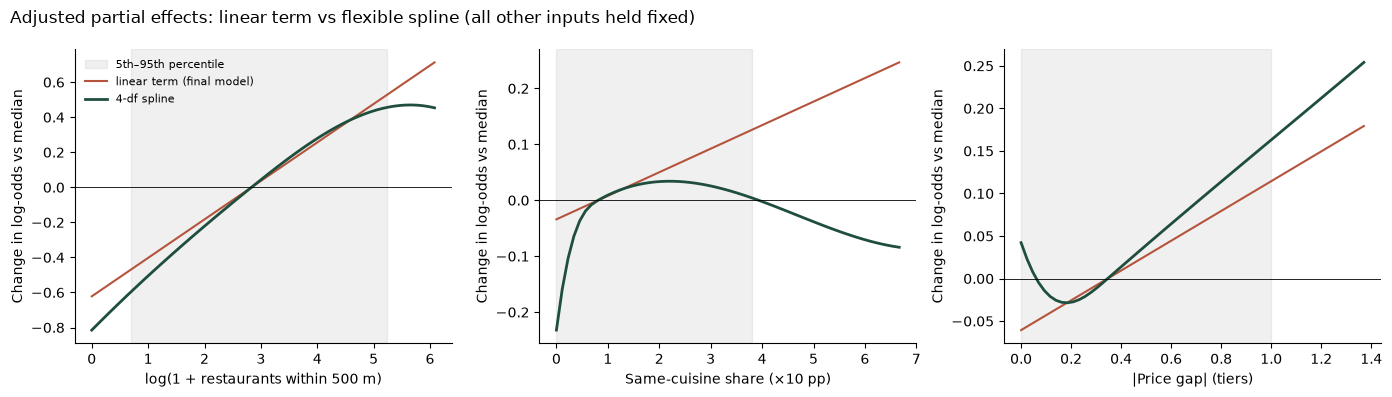

In [14]:
CONT = {"log_n_rest_500m": "log(1 + restaurants within 500 m)",
        "same_cuisine_share_10pp": "Same-cuisine share (×10 pp)",
        "abs_price_gap": "|Price gap| (tiers)"}

rows, spline_models = [], {}
for x in CONT:
    m_s = fit_logit(formulas[FINAL].replace(x, f"bs({x}, df=4)"))
    spline_models[x] = m_s
    lr = 2 * (m_s.llf - final.llf)
    d = int(m_s.df_model - final.df_model)
    rows.append({"variable": CONT[x], "LR_stat": lr, "df": d, "p_value": stats.chi2.sf(lr, d),
                 "AIC_linear": final.aic, "AIC_spline": m_s.aic, "AIC_gain": final.aic - m_s.aic})
display(pd.DataFrame(rows).set_index("variable").style.format(
    {"LR_stat": "{:.1f}", "p_value": "{:.2g}", "AIC_linear": "{:,.0f}", "AIC_spline": "{:,.0f}", "AIC_gain": "{:.1f}"}))

# Partial effects: vary one input over its range, hold everything else at one typical restaurant
typical = df.iloc[[0]].copy()
for c in ["price_tier", "cuisine_group", "metro"]:
    typical[c] = df[c].mode()[0]
for c in ["is_chain", "price_gap_missing"]:
    typical[c] = 0
for c in CONT:
    typical[c] = df[c].median()

def logit_of(p):
    p = np.asarray(p)
    return np.log(p / (1 - p))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, label) in zip(axes, CONT.items()):
    lo_q, hi_q = df[x].quantile([0.05, 0.95])
    grid = np.linspace(df[x].min(), df[x].quantile(0.99), 60)
    new = pd.concat([typical] * len(grid), ignore_index=True)
    new[x] = grid
    lin = logit_of(final.predict(new)) - logit_of(final.predict(typical))[0]
    spl = logit_of(spline_models[x].predict(new)) - logit_of(spline_models[x].predict(typical))[0]
    ax.axvspan(lo_q, hi_q, color=GREY, alpha=0.12, label="5th–95th percentile")
    ax.plot(grid, lin, color=RUST, linewidth=1.5, label="linear term (final model)")
    ax.plot(grid, spl, color=GREEN, linewidth=2, label="4-df spline")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xlabel(label)
    ax.set_ylabel("Change in log-odds vs median")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Adjusted partial effects: linear term vs flexible spline (all other inputs held fixed)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

**Result.**
- **Density:** the spline tracks the straight line closely across the 5th–95th percentile range. It is slightly steeper at the low end and flattens only above the 95th percentile. AIC gain ≈ 23 out of ≈ 62,000: a small curvature. This confirms that the log transform from notebook 01 was the right choice.
- **Price gap:** close to linear (AIC gain ≈ 0.3, p ≈ 0.10). The small dip near 0 is not meaningful.
- **Same-cuisine share: the linear term is misleading.** The spline jumps from share 0 to about 0.5 (5%) and then stays flat, even drifting down in the thin upper tail. So the risk does not grow steadily with saturation. What seems to matter is having **any** same-cuisine competitor nearby. The next cell tests this directly.

In [15]:
# Alternative coding: "at least one same-cuisine restaurant within 500 m" instead of (or alongside) the share
df["has_same_cuisine_nbr"] = (df["n_same_cuisine_500m"] > 0).astype(int)
print(f"Restaurants with at least one same-cuisine neighbour within 500 m: {df['has_same_cuisine_nbr'].mean():.1%}")

alt_specs = {
    "share only (main model)": formulas[FINAL],
    "any same-cuisine neighbour only": formulas[FINAL].replace("same_cuisine_share_10pp", "has_same_cuisine_nbr"),
    "both": formulas[FINAL].replace("same_cuisine_share_10pp", "has_same_cuisine_nbr + same_cuisine_share_10pp"),
}
rows = []
for name, f in alt_specs.items():
    m_alt = fit_logit(f)
    row = {"specification": name, "AIC": m_alt.aic}
    for t, lbl in [("has_same_cuisine_nbr", "OR any same-cuisine nbr"), ("same_cuisine_share_10pp", "OR share +10pp"),
                   ("log_n_rest_500m", "OR log density")]:
        if t in m_alt.params:
            row[lbl] = np.exp(m_alt.params[t])
            row[f"p ({lbl[3:]})"] = m_alt.pvalues[t]
    rows.append(row)
display(pd.DataFrame(rows).set_index("specification").style.format(
    {c: "{:.3f}" for c in ["OR any same-cuisine nbr", "OR share +10pp", "OR log density"]} |
    {c: "{:.2g}" for c in ["p (any same-cuisine nbr)", "p (share +10pp)", "p (log density)"]} | {"AIC": "{:,.1f}"},
    na_rep="–"))

Restaurants with at least one same-cuisine neighbour within 500 m: 71.1%


,AIC,OR share +10pp,p (share +10pp),OR log density,p (log density),OR any same-cuisine nbr,p (any same-cuisine nbr)
specification,,,,,,,
share only (main model),"61,916.8",1.043,9.2e-09,1.246,8.5e-143,–,–
any same-cuisine neighbour only,"61,864.5",–,–,1.187,9.4e-68,1.277,4.9e-20
both,"61,866.4",1.003,0.73,1.189,1.1e-57,1.269,5.2e-13


**Reading the alternative coding.** Once the model knows whether a restaurant has **at least one** same-cuisine competitor within 500 m (OR ≈ 1.28, about 28% higher odds), the share adds nothing (OR ≈ 1.00, p ≈ 0.7). The yes/no version also fits better than the linear share (AIC about 50 lower), about as well as the spline. Note that the density odds ratio falls a little (≈ 1.25 → 1.19), because a restaurant in a dense area is more likely to have a same-cuisine neighbour.

**What we do with this.** The main model keeps the pre-agreed specification from notebook 01 (the share), so the block analysis stays comparable across the team. But the report should describe the effect as **"having a direct same-cuisine competitor nearby"**, not as "each extra 10 points of saturation", and notebook 03 should validate the yes/no version as the preferred alternative.

### 6c. Influential observations

**Cook's distance** measures how much all the fitted values would change if one restaurant were dropped; **leverage** (hat value) measures how unusual a restaurant's combination of inputs is.

The textbook cut-off, Cook's D > 4/*n*, is not a good *refit* rule for a logistic regression with 52,000 rows. It flags about 2% of restaurants, almost all of them **closed restaurants the model expected to stay open**. Dropping that group selects on the outcome and biases every coefficient (we tried it: the `Missing` price tier flips from 0.43 to 2.0, purely because a fifth of its closures are removed). Instead we use a graded test: drop the **0.1%** and then the **0.5%** most influential restaurants, refit, and see which odds ratios move.

In [16]:
infl = final.get_influence(observed=False)
cooks = infl.cooks_distance[0]
leverage = infl.hat_matrix_diag
n, k = len(df), int(final.df_model) + 1
order = np.argsort(-cooks)
flag_4n = cooks > 4 / n
print(f"Max Cook's distance: {cooks.max():.5f} (rule-of-thumb concern starts near 0.5–1)")
print(f"Above 4/n = {4/n:.1e}: {flag_4n.sum():,} restaurants, of which {df[TARGET].to_numpy()[flag_4n].mean():.0%} are closed")
print(f"Max leverage: {leverage.max():.4f}; average leverage k/n = {k/n:.5f}")

top = df.iloc[order[:8]][["name", "metro", "price_tier", "cuisine_group", "is_chain", "n_rest_500m",
                          "abs_price_gap", TARGET]].assign(cooks_d=cooks[order[:8]],
                                                           predicted_p=final.fittedvalues.to_numpy()[order[:8]])
print("\nMost influential restaurants:")
display(top.round(4))

sens = pd.DataFrame({"OR_all": np.exp(final.params)})
for share in [0.001, 0.005]:
    drop = np.zeros(n, dtype=bool)
    drop[order[:int(round(share * n))]] = True
    m_drop = fit_logit(formulas[FINAL], data=df.loc[~drop])
    col = f"drop top {share:.1%}"
    sens[col] = np.exp(m_drop.params)
    sens[f"change_% ({share:.1%})"] = 100 * (sens[col] / sens["OR_all"] - 1)
sens["direction"] = np.where(np.sign(np.log(sens["drop top 0.5%"])) != np.sign(np.log(sens["OR_all"])), "FLIPS", "same")
sens.index = [nice_label(t) for t in sens.index]
sens = sens.drop(index="Intercept")
fmt = lambda s: (s.style.format("{:.3f}", subset=["OR_all", "drop top 0.1%", "drop top 0.5%"])
                 .format("{:+.1f}", subset=["change_% (0.1%)", "change_% (0.5%)"]))
print("Odds ratios after dropping the most influential restaurants (largest changes first):")
display(fmt(sens.reindex(sens["change_% (0.5%)"].abs().sort_values(ascending=False).index).head(10)))
core = ["Chain (5+ locations)", "log(1 + restaurants within 500 m)", "Same-cuisine share, +10 pp", "|Price gap| (tiers)"]
print("Core variables:")
display(fmt(sens.loc[core]))

Max Cook's distance: 0.00064 (rule-of-thumb concern starts near 0.5–1)
Above 4/n = 7.7e-05: 1,265 restaurants, of which 91% are closed
Max leverage: 0.0080; average leverage k/n = 0.00063

Most influential restaurants:


,name,metro,price_tier,cuisine_group,is_chain,n_rest_500m,abs_price_gap,closed,cooks_d,predicted_p
45144,Haggen Food & Pharmacy,Santa Barbara,4,Sandwiches & Delis,1,4,2.5000,1,0.0006,0.1525
18634,Little Tokyo,St. Louis,4,Japanese & Sushi,1,14,2.7692,1,0.0006,0.1896
6299,State & Lemp,Boise,4,Burgers & Fast Food,0,3,2.5000,1,0.0005,0.2266
6416,Yellow Springs Inn,Philadelphia,4,American,0,0,0.0000,1,0.0005,0.2908
40789,Morton's The Steakhouse,St. Louis,4,Seafood,1,96,2.0116,1,0.0005,0.2229
40046,World of Beer,Tampa,4,Bars & Pubs,1,52,2.0256,1,0.0005,0.2187
20082,McClintock's Restaurant,Tucson,4,American,0,0,0.0000,1,0.0005,0.3232
8564,Morton's The Steakhouse,Indianapolis,4,Seafood,1,243,2.2156,1,0.0005,0.2522


Odds ratios after dropping the most influential restaurants (largest changes first):


,OR_all,drop top 0.1%,change_% (0.1%),drop top 0.5%,change_% (0.5%),direction
Price tier: 4 (vs 1),0.662,0.413,-37.7,0.146,-78.0,same
Price tier: Missing (vs 1),0.427,0.428,+0.2,0.533,+24.9,same
Price gap missing,1.116,1.111,-0.4,0.875,-21.6,FLIPS
Metro: Boise (vs Philadelphia),0.823,0.818,-0.5,0.720,-12.5,same
Metro: Edmonton (vs Philadelphia),0.800,0.796,-0.5,0.762,-4.7,same
Metro: Santa Barbara (vs Philadelphia),1.135,1.128,-0.6,1.089,-4.0,same
Price tier: 3 (vs 1),0.922,0.921,-0.2,0.886,-4.0,same
Chain (5+ locations),0.357,0.356,-0.4,0.345,-3.2,same
Cuisine: Other (vs Burgers & Fast Food),1.398,1.394,-0.3,1.359,-2.8,same
Cuisine: Japanese & Sushi (vs Burgers & Fast Food),1.102,1.098,-0.3,1.078,-2.2,same


Core variables:


,OR_all,drop top 0.1%,change_% (0.1%),drop top 0.5%,change_% (0.5%),direction
Chain (5+ locations),0.357,0.356,-0.4,0.345,-3.2,same
log(1 + restaurants within 500 m),1.246,1.248,+0.2,1.252,+0.5,same
"Same-cuisine share, +10 pp",1.043,1.043,-0.0,1.038,-0.5,same
|Price gap| (tiers),1.191,1.188,-0.3,1.191,-0.0,same


**Result.**
- **No single restaurant matters.** The largest Cook's distance (≈ 0.0006) is about a thousand times below the usual level of concern, and the largest leverage is under 0.01. The 4/*n* rule flags restaurants that are 91% closed, which confirms why it should not be used to drop data.
- **The most influential restaurants are all $$$$ restaurants that closed** while the model gave them a low risk (15–32%). The $$$$ tier is the smallest cell (194 restaurants, 81 closures), so each closure carries weight.
- **The core findings are robust.** Chain, density, same-cuisine share and price gap change by at most about 3% when the top 0.5% most influential restaurants are dropped, and none changes direction.
- **Fragile estimates:**
  - the **$$$$** odds ratio swings from 0.66 to 0.41 (drop 0.1%) and 0.15 (drop 0.5%);
  - **`price_gap_missing`** flips direction (it was not significant anyway);
  - the **`Missing` price tier** and **Boise** move by 10–25% when the top 0.5% are dropped.

  These rest on rare cells, so the report should state their direction cautiously and not quote precise magnitudes.

### 6d. Calibration and goodness of fit

**Hosmer–Lemeshow test.** Sort restaurants into 10 groups by predicted risk, then compare the observed and expected number of closures in each group with a χ² statistic (8 df). H<sub>0</sub>: the model is well calibrated. With *n* = 52,000 the test is very sensitive, so the calibration plot is the more useful check: points on the diagonal mean "predicted 40%" really does mean about 40% closed.

Hosmer–Lemeshow: chi2 = 24.2, df = 8, p = 0.00213


,n,mean_predicted,observed_rate,observed,expected
decile,,,,,
1,5227,0.124,0.121,635,650
2,5227,0.172,0.166,868,897
3,5227,0.205,0.203,1061,"1,069"
4,5229,0.263,0.265,1387,"1,374"
5,5226,0.321,0.313,1638,"1,677"
6,5225,0.360,0.362,1891,"1,880"
7,5226,0.393,0.414,2161,"2,053"
8,5227,0.429,0.437,2285,"2,243"
9,5227,0.478,0.484,2528,"2,499"


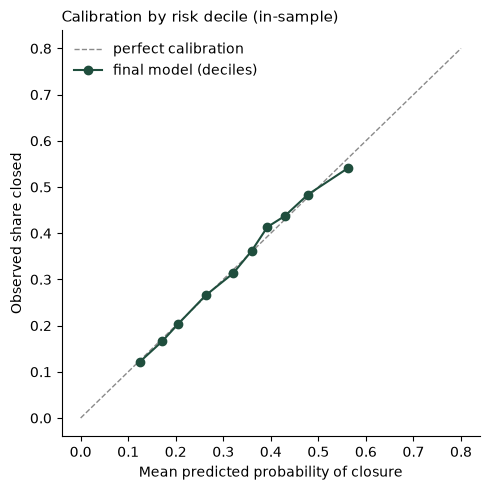

In [17]:
p_hat = final.fittedvalues.to_numpy()
y = df[TARGET].to_numpy()
decile = pd.qcut(p_hat, 10, labels=False)
cal = (pd.DataFrame({"decile": decile + 1, "p": p_hat, "y": y}).groupby("decile")
       .agg(n=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"),
            observed=("y", "sum"), expected=("p", "sum")))
hl = (((cal["observed"] - cal["expected"]) ** 2) / (cal["expected"] * (1 - cal["expected"] / cal["n"]))).sum()
hl_p = stats.chi2.sf(hl, 8)
print(f"Hosmer–Lemeshow: chi2 = {hl:.1f}, df = 8, p = {hl_p:.3g}")
display(cal.style.format({"mean_predicted": "{:.3f}", "observed_rate": "{:.3f}", "expected": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 0.8], [0, 0.8], color=GREY, linestyle="--", linewidth=1, label="perfect calibration")
ax.plot(cal["mean_predicted"], cal["observed_rate"], marker="o", color=GREEN, label="final model (deciles)")
ax.set_xlabel("Mean predicted probability of closure")
ax.set_ylabel("Observed share closed")
ax.set_title("Calibration by risk decile (in-sample)", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Result.** The calibration points lie close to the diagonal, from the lowest-risk decile (12% closed) to the highest (54%). In every decile the predicted and observed rates are within about 2 percentage points. The largest gaps are a slight underprediction in decile 7 (39% predicted, 41% observed) and a slight overprediction in the top decile (56% predicted, 54% observed). The Hosmer–Lemeshow test rejects (p ≈ 0.002), but at *n* = 52,000 it detects gaps of this size, which make no practical difference to a risk score. The model's probabilities mean what they say, at least in-sample, and they spread restaurants over a useful range of risk.

### 6e. Binned residual plot

Raw residuals of a logistic regression take only two values for each fitted probability, so plotting them directly is useless. Instead (Gelman & Hill, 2007) we split the fitted probabilities into 50 bins and plot the **average residual** (observed − predicted) in each bin, with ±2 standard-error bands, 2·√(p̄(1 − p̄)/n<sub>bin</sub>). For a well-specified model about 95% of points fall inside the bands, with no pattern.

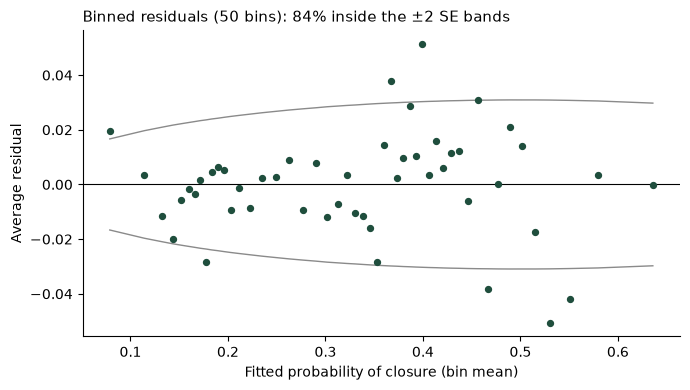

In [18]:
resid = y - p_hat
bins = pd.qcut(p_hat, 50, labels=False, duplicates="drop")
br = pd.DataFrame({"p": p_hat, "r": resid, "bin": bins}).groupby("bin").agg(p=("p", "mean"), r=("r", "mean"), n=("r", "size"))
br["band"] = 2 * np.sqrt(br["p"] * (1 - br["p"]) / br["n"])
inside = (br["r"].abs() <= br["band"]).mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(br["p"], br["band"], color=GREY, linewidth=1)
ax.plot(br["p"], -br["band"], color=GREY, linewidth=1)
ax.scatter(br["p"], br["r"], color=GREEN, s=18, zorder=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Fitted probability of closure (bin mean)")
ax.set_ylabel("Average residual")
ax.set_title(f"Binned residuals (50 bins): {inside:.0%} inside the ±2 SE bands", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Result.** The binned residuals scatter around zero with no trend in the low-risk range (below about 0.35). About 84% of the bins fall inside the ±2 SE bands, against roughly 95% expected for a perfectly specified model. The misses are in the 0.35–0.55 range and go both ways, matching the small calibration gaps above. Their size, at most about 5 percentage points in a bin of ~1,000 restaurants, is small next to the spread of predicted risks. Most likely they reflect what the model leaves out (rent, management, local shocks) rather than a wrong functional form, since the spline checks found no large non-linearity apart from same-cuisine share.

### Diagnostics summary

| Check | Result | Action |
|---|---|---|
| Separation / sparse cells | Smallest cell ($$$$) has 194 restaurants, 81 closures; no separation | Report its wide CI |
| Multicollinearity (GVIF) | All fine except `price_gap_missing` (≈ 2.7), which overlaps with the Missing price tier by construction | Keep; note its inflated SE |
| Linearity of the logit | Density and price gap ≈ linear. Same-cuisine share is not: the effect is "any same-cuisine neighbour" (yes/no) | Describe it as yes/no in the report; validate the yes/no version in 03 |
| Influence (Cook's D) | No influential single restaurant; core odds ratios move ≤ 3% after dropping the top 0.5% | Treat $$$$, Missing tier and `price_gap_missing` as fragile |
| Calibration | Deciles within ~2 pp of the diagonal (in-sample); H–L rejects at this *n* | Re-check out-of-sample in 03 |
| Binned residuals | 84% of bins inside ±2 SE; small two-sided misses at mid-high risk | None; consistent with the modest fit |
| Independence | Nearby restaurants are correlated (density SE ×1.6 when clustered) | Report grid-clustered p-values (Step 5) |

## Step 7 — Save outputs for the team

| File | For |
|---|---|
| `outputs/block_comparison.csv` | Report: model-building table |
| `outputs/odds_ratios_final.csv` | Report: main results table (odds ratios, default and clustered p-values) |
| `outputs/model_formula.txt` | Notebook 03: the exact formulas for every block, so validation refits the same model |
| `../reports/figures/odds_ratios.png` | Deck and report (saved in Step 4) |

In [19]:
block_comparison.to_csv(os.path.join(OUTPUT_DIR, "block_comparison.csv"))

or_out = or_table.copy()
or_out["p_value_clustered"] = final_cl.pvalues.to_numpy()
or_out["ci_low_clustered"] = np.exp(final_cl.conf_int()[0]).to_numpy()
or_out["ci_high_clustered"] = np.exp(final_cl.conf_int()[1]).to_numpy()
or_out.index.name = "term"
or_out.to_csv(os.path.join(OUTPUT_DIR, "odds_ratios_final.csv"))

with open(os.path.join(OUTPUT_DIR, "model_formula.txt"), "w", encoding="utf-8") as fh:
    fh.write("# Logistic regression formulas (statsmodels / patsy syntax), one per block\n")
    fh.write("# Requires: df['same_cuisine_share_10pp'] = df['same_cuisine_share_500m'] * 10; price_tier read as str\n")
    for name, f in formulas.items():
        fh.write(f"{name}: {f}\n")
print("Saved:", ", ".join(["block_comparison.csv", "odds_ratios_final.csv", "model_formula.txt"]),
      "to", OUTPUT_DIR, "and odds_ratios.png to", FIG_DIR)

Saved: block_comparison.csv, odds_ratios_final.csv, model_formula.txt to outputs and odds_ratios.png to ../reports/figures


## Summary and hand-off to notebook 03

**Findings (in-sample, all effects adjusted for the other variables):**
1. **Chains** have about 64% lower odds of closure than independents, the strongest effect.
2. **Density** is the main location risk: each doubling of nearby restaurants raises the odds of closure by about 16%.
3. Having a **same-cuisine competitor within 500 m** (about 28% higher odds) and **pricing away from the neighbourhood** (about 19% higher odds per tier of gap) add smaller but robust risk.
4. **Cuisine** matters (American, Italian, Mediterranean highest; fast food, pizza, Mexican and Chinese lowest). **Price tier** matters little once location is known; the $$$$ and "Missing" effects rest on thin or artifact-prone data.
5. Every block adds significant fit; concept and competition do almost all the work. Overall fit is modest (AUC ≈ 0.675 in-sample), as expected without rent, management or capital data. Calibration is good in-sample.

**For the validation notebook (03):**
- [ ] **Held-out metro and the metro block:** a metro left out of training has no coefficient, so B4 cannot score it directly. Either validate the **B3 model** (no metro dummies) on the held-out metro, or score it at the reference (Philadelphia) level and say so. The block table shows B3 and B4 fit almost equally well, so B3 loses little.
- [ ] Compare with a naive baseline (the training closure rate, or chain-only) on AUC and calibration.
- [ ] Validate the **yes/no same-cuisine competitor** version (`has_same_cuisine_nbr = n_same_cuisine_500m > 0`) next to the main model; it fits better in-sample.
- [ ] Robustness: 250 m and 1 km radii, chain cutoffs 3 and 10, open-neighbour counts.
- [ ] Quote the grid-clustered p-values (`p_value_clustered` in `odds_ratios_final.csv`) in the report.
- [ ] Treat the `price_tier = Missing` effect as a data artifact, not advice, and the $$$$ effect as fragile (Step 6c).